In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

In [6]:
train = pd.read_csv(
    "../data/raw/train.csv",
    parse_dates=["date"]
)


test = pd.read_csv(
    "../data/raw/test.csv",
    parse_dates=["date"]
)

stores = pd.read_csv("../data/raw/stores.csv")

oil = pd.read_csv(
    "../data/raw/oil.csv",
    parse_dates=["date"]
)

holidays = pd.read_csv(
    "../data/raw/holidays_events.csv",
    parse_dates=["date"]
)

transactions = pd.read_csv(
    "../data/raw/transactions.csv",
    parse_dates=["date"]
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [7]:
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


#### Check the dataset dimension

In [8]:
datasets = {
    "Train": train,
    "Test": test,
    "Stores": stores,
    "Oil": oil,
    "Holidays": holidays,
    "Transactions": transactions
}

for name, df in datasets.items():

    print(f"\n{name} Dataset")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


Train Dataset
Rows: 3000888
Columns: 6

Test Dataset
Rows: 28512
Columns: 5

Stores Dataset
Rows: 54
Columns: 5

Oil Dataset
Rows: 1218
Columns: 2

Holidays Dataset
Rows: 350
Columns: 6

Transactions Dataset
Rows: 83488
Columns: 3


In [9]:
train.describe()

,id,date,store_nbr,sales,onpromotion
count,3.000888e+06,3000888,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2015-04-24 08:27:04.703088,2.750000e+01,3.577757e+02,2.602770e+00
min,0.000000e+00,2013-01-01 00:00:00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,2014-02-26 18:00:00,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2015-04-24 12:00:00,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,2016-06-19 06:00:00,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,2017-08-15 00:00:00,5.400000e+01,1.247170e+05,7.410000e+02
std,8.662819e+05,NaN,1.558579e+01,1.101998e+03,1.221888e+01


In [10]:
train.describe(include="object")

,family
count,3000888
unique,33
top,AUTOMOTIVE
freq,90936


In [11]:
### Missing Values

missing_report = pd.DataFrame({
    "Missing_Count": train.isnull().sum(),
    "Missing_Percentage": (
        train.isnull().sum() / len(train) * 100
    )
})

missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage
id,0,0.0
date,0,0.0
store_nbr,0,0.0
family,0,0.0
sales,0,0.0
onpromotion,0,0.0


In [12]:
for name, df in datasets.items():

    print(
        name,
        "Duplicate rows:",
        df.duplicated().sum()
    )

Train Duplicate rows: 0
Test Duplicate rows: 0
Stores Duplicate rows: 0
Oil Duplicate rows: 0
Holidays Duplicate rows: 0
Transactions Duplicate rows: 0


In [13]:
train.duplicated(
    subset=["date", "store_nbr", "family"]
).sum()

np.int64(0)

In [ ]:
#### Busiin

In [14]:
print("Start Date:", train["date"].min())
print("End Date:", train["date"].max())

print("Total Days:", train["date"].nunique())

Start Date: 2013-01-01 00:00:00
End Date: 2017-08-15 00:00:00
Total Days: 1684


#### Number of unique stores

In [15]:
print(
    "Total Stores:",
    train["store_nbr"].nunique()
)

Total Stores: 54


In [16]:
print(
    "Total Product Families:",
    train["family"].nunique()
)

Total Product Families: 33


#### Highest-selling product categories

In [19]:
product_sales = (
    train.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
)

product_sales

family
GROCERY I                     3.434627e+08
BEVERAGES                     2.169545e+08
PRODUCE                       1.227047e+08
CLEANING                      9.752129e+07
DAIRY                         6.448771e+07
BREAD/BAKERY                  4.213395e+07
POULTRY                       3.187600e+07
MEATS                         3.108647e+07
PERSONAL CARE                 2.459205e+07
DELI                          2.411032e+07
HOME CARE                     1.602274e+07
EGGS                          1.558830e+07
FROZEN FOODS                  1.407389e+07
PREPARED FOODS                8.799895e+06
LIQUOR,WINE,BEER              7.746640e+06
SEAFOOD                       2.015432e+06
GROCERY II                    1.962767e+06
HOME AND KITCHEN I            1.861491e+06
HOME AND KITCHEN II           1.520670e+06
CELEBRATION                   7.611770e+05
LINGERIE                      6.531140e+05
LADIESWEAR                    6.511590e+05
PLAYERS AND ELECTRONICS       5.626080e+05
AUTO

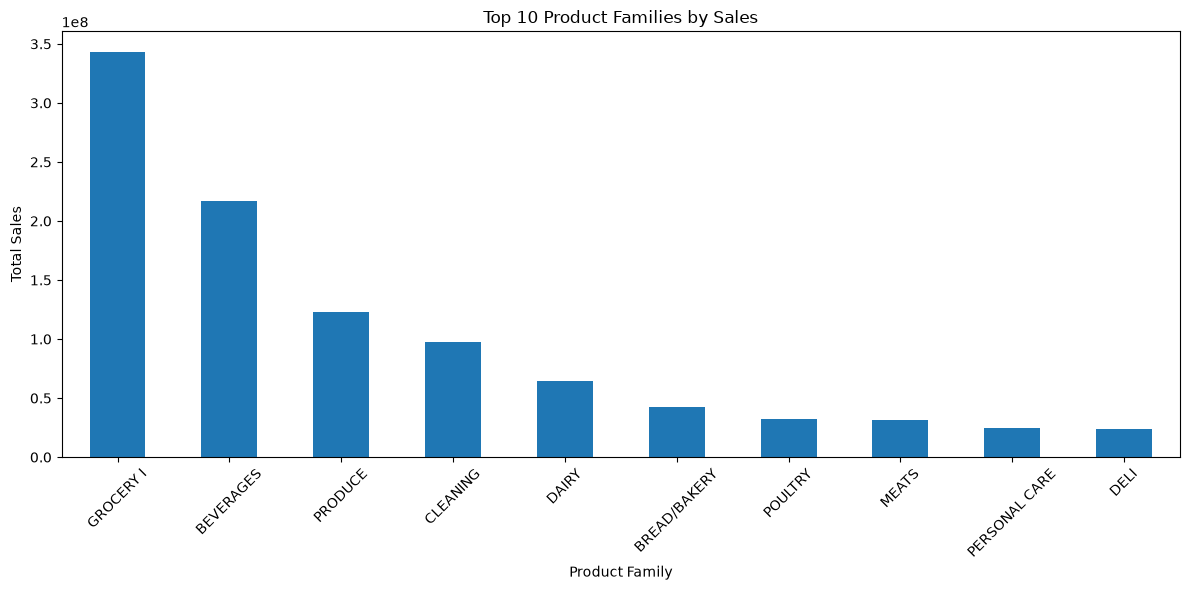

In [20]:
plt.figure(figsize=(12, 6))

product_sales.head(10).plot(
    kind="bar",
    title="Top 10 Product Families by Sales"
)

plt.xlabel("Product Family")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Highest Selling Store


In [24]:
store_sales = (
    train.groupby("store_nbr")["sales"]
    .sum()
    .sort_values(ascending=False)
)

store_sales.head(10)

store_nbr
44    6.208755e+07
45    5.449801e+07
47    5.094831e+07
3     5.048191e+07
49    4.342010e+07
46    4.189606e+07
48    3.593313e+07
51    3.291149e+07
8     3.049429e+07
50    2.865302e+07
Name: sales, dtype: float64

### Average sales by weekday

In [25]:
train["day_of_week"] = train["date"].dt.day_name()

weekday_sales = (
    train.groupby("day_of_week")["sales"]
    .mean()
)

weekday_sales

day_of_week
Friday       325.238138
Monday       346.544732
Saturday     433.336472
Sunday       463.085366
Thursday     283.540517
Tuesday      319.823843
Wednesday    332.909401
Name: sales, dtype: float64

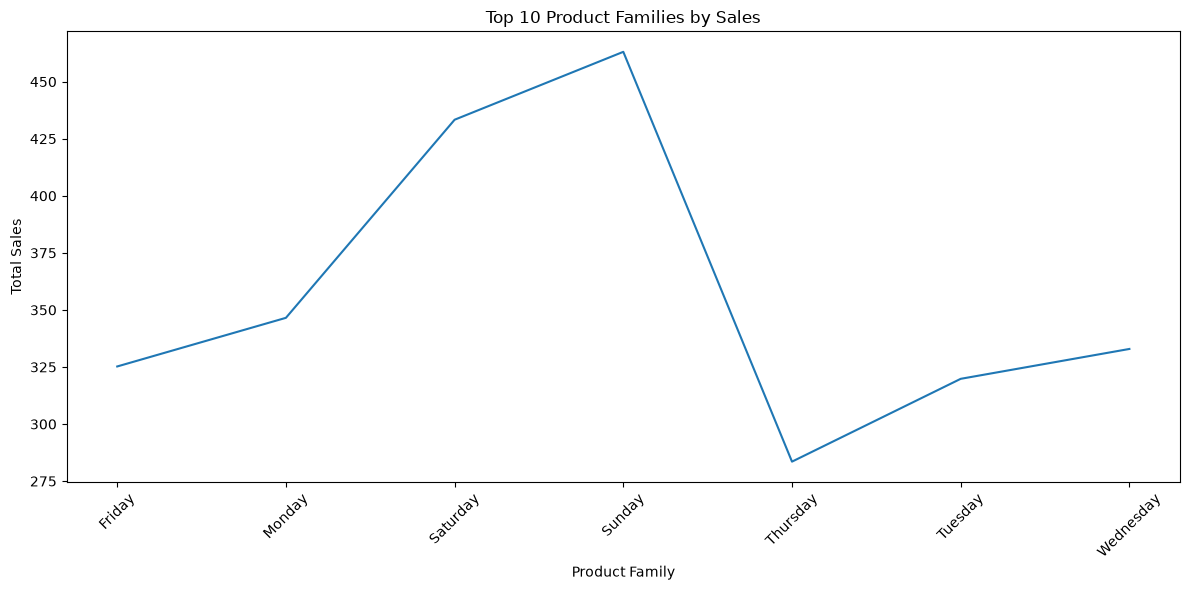

In [26]:
plt.figure(figsize=(12, 6))

weekday_sales.head(10).plot(
    kind="line",
    marker='*',
    markersize=5,
    title="Top 10 Product Families by Sales",
)

plt.xlabel("Product Family")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Monthly sales analysis

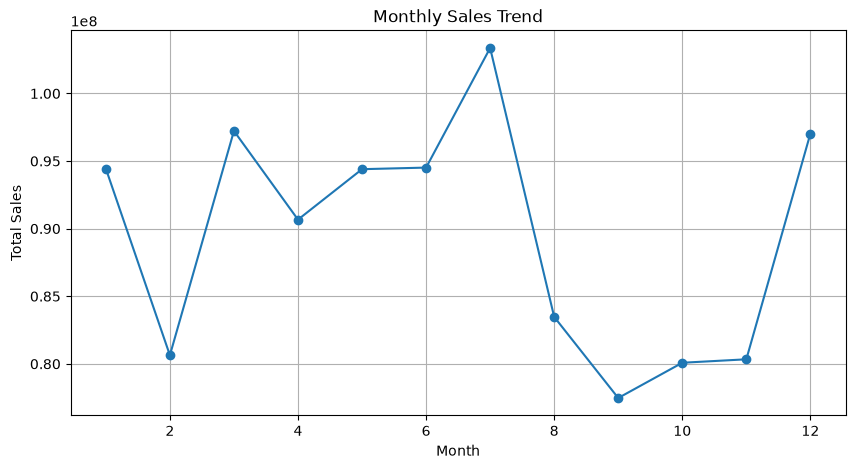

In [27]:
train["month"] = train["date"].dt.month

monthly_sales = (
    train.groupby("month")["sales"]
    .sum()
)

monthly_sales.plot(
    figsize=(10, 5),
    marker="o",
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid()
plt.show()

#### Generating the Report

In [28]:
data_quality_report = []

for name, df in datasets.items():

    data_quality_report.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing_Values": df.isnull().sum().sum(),
        "Duplicate_Rows": df.duplicated().sum()
    })

quality_df = pd.DataFrame(data_quality_report)

quality_df

,Dataset,Rows,Columns,Missing_Values,Duplicate_Rows
0,Train,3000888,8,0,0
1,Test,28512,5,0,0
2,Stores,54,5,0,0
3,Oil,1218,2,43,0
4,Holidays,350,6,0,0
5,Transactions,83488,3,0,0


In [30]:
quality_df.to_csv(
    "../reports/phase1_data_quality_report.csv",
    index=False
)